In [8]:
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [6]:
df = pd.read_csv(r"C:\Madhuri\class\EDA\archive (7).zip", compression='zip')
print(df.head())

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [18]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

 Understanding Product Categories

1.1

In [7]:
freq_table = df['category'].value_counts().reset_index()
freq_table.columns = ['Category', 'Count']

print("Top 5 most listed product categories:")
print(freq_table.head(5))

Top 5 most listed product categories:
                                 Category   Count
0                       Sports & Outdoors  836265
1                                  Beauty   19312
2  Handmade Clothing, Shoes & Accessories   19229
3                             Bath & Body   19092
4                          Birthday Gifts   18978


1.2

C:\Users\Naveen\AppData\Local\Temp\ipykernel_13216\2070175226.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Category', data=freq_table.head(20), palette="viridis")


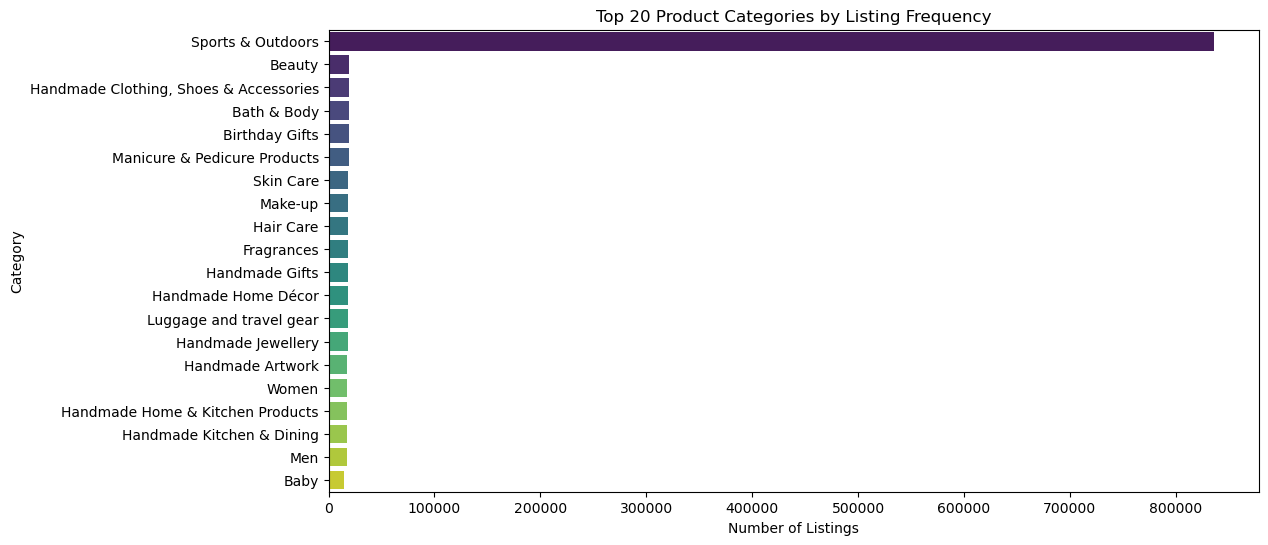

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x='Count', y='Category', data=freq_table.head(20), palette="viridis")
plt.title("Top 20 Product Categories by Listing Frequency")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.show()

Delving into Product Pricing

2.1

In [11]:
# Convert price to numeric (strip currency symbols, commas, etc.)
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace('[^0-9\\.]', '', regex=True), errors='coerce')

# Drop missing or zero values if necessary
price = df['price'].dropna()

In [12]:
mean_price = price.mean()
median_price = price.median()
mode_price = price.mode()[0] if not price.mode().empty else np.nan

print("Measures of Centrality:")
print(f"Mean   : {mean_price:.2f}")
print(f"Median : {median_price:.2f}")
print(f"Mode   : {mode_price:.2f}")

Measures of Centrality:
Mean   : 89.24
Median : 19.09
Mode   : 9.99


2.2

In [13]:
variance = price.var()
std_dev = price.std()
price_range = price.max() - price.min()
iqr = price.quantile(0.75) - price.quantile(0.25)

print("\nMeasures of Dispersion:")
print(f"Variance : {variance:.2f}")
print(f"Std Dev  : {std_dev:.2f}")
print(f"Range    : {price_range:.2f} (Min={price.min():.2f}, Max={price.max():.2f})")
print(f"IQR      : {iqr:.2f}")


Measures of Dispersion:
Variance : 119445.49
Std Dev  : 345.61
Range    : 100000.00 (Min=0.00, Max=100000.00)
IQR      : 36.00


2.3

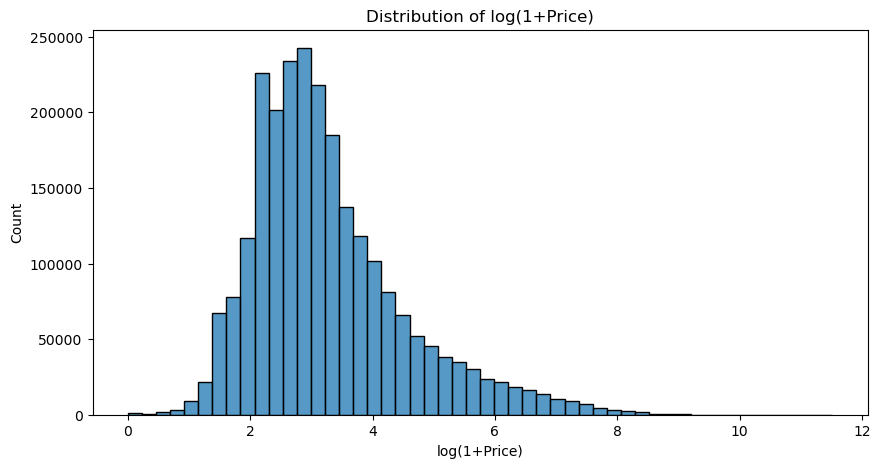

In [15]:
plt.figure(figsize=(10,5))
sns.histplot(np.log1p(price), bins=50, kde=False)
plt.title("Distribution of log(1+Price)")
plt.xlabel("log(1+Price)")
plt.ylabel("Count")
plt.show()

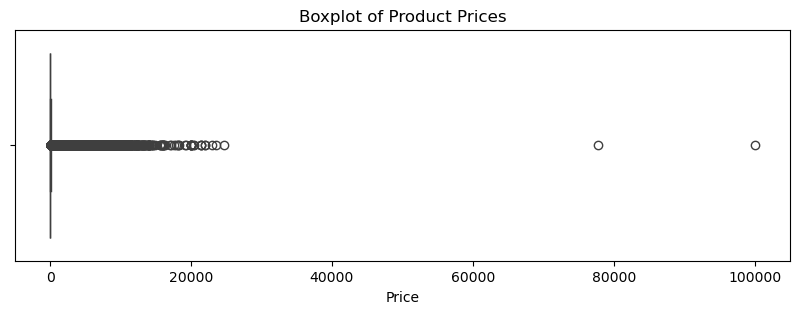

In [16]:
plt.figure(figsize=(10,3))
sns.boxplot(x=price)
plt.title("Boxplot of Product Prices")
plt.xlabel("Price")
plt.show()

Unpacking Product Ratings

3.1

In [22]:
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

ratings = df['stars'].dropna()

In [25]:
mean_rating = ratings.mean()
median_rating = ratings.median()
mode_rating = ratings.mode()[0] if not ratings.mode().empty else np.nan

print("Measures of Centrality:")
print(f"Mean   : {mean_rating:.2f}")
print(f"Median : {median_rating:.2f}")
print(f"Mode   : {mode_rating:.2f}")

Measures of Centrality:
Mean   : 2.15
Median : 0.00
Mode   : 0.00


In [26]:
variance = ratings.var()
std_dev = ratings.std()
iqr = ratings.quantile(0.75) - ratings.quantile(0.25)

print("\nMeasures of Dispersion:")
print(f"Variance : {variance:.3f}")
print(f"Std Dev  : {std_dev:.3f}")
print(f"IQR      : {iqr:.3f}")


Measures of Dispersion:
Variance : 4.817
Std Dev  : 2.195
IQR      : 4.400


In [27]:
from scipy.stats import skew, kurtosis

skewness = skew(ratings, nan_policy='omit')
kurt = kurtosis(ratings, nan_policy='omit')

print("\nShape of the Distribution:")
print(f"Skewness : {skewness:.3f}")
print(f"Kurtosis : {kurt:.3f}")


Shape of the Distribution:
Skewness : 0.081
Kurtosis : -1.926


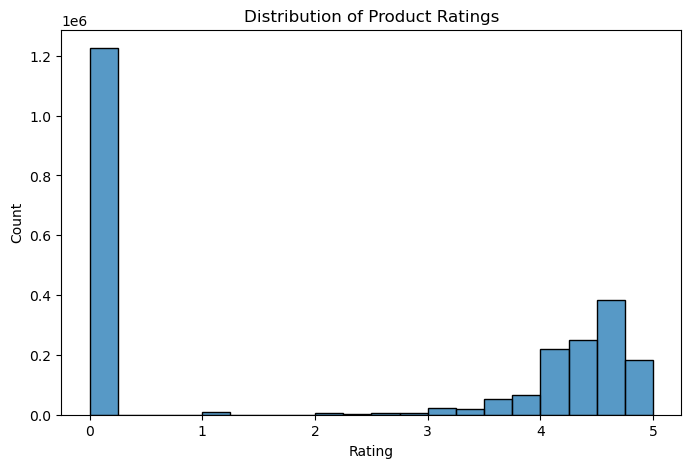

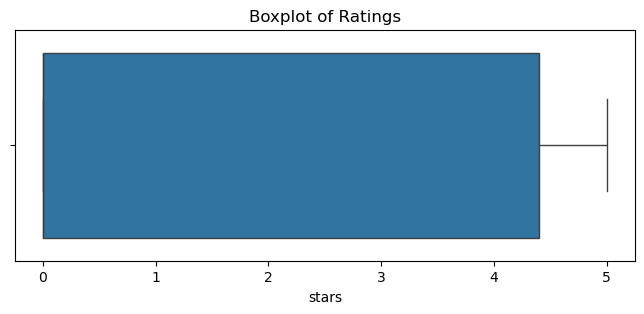

In [28]:
# Histogram
plt.figure(figsize=(8,5))
sns.histplot(ratings, bins=20, kde=False)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

# Boxplot for compact view
plt.figure(figsize=(8,3))
sns.boxplot(x=ratings)
plt.title("Boxplot of Ratings")
plt.show()